# Chapter 38: Mixing: graphs, noise schedules and guidance

Checks [chapter 38](../../book/38-mixing.md). The models are small and exact: a graph layer is a row-stochastic weight
matrix acting on node values, a noising step is the pair (signal share, noise share), guidance is a blend of two
prediction vectors, an augmented model is a function averaged over the circular shifts of its input, a policy is a
softmax over four actions, and the random vector has random-sign coordinates. Everything is NumPy in float64, seeded.
These are measurements, not proofs: the proofs are in `Mixing.lean` and `OnAverage.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import itertools
import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 38


def apply_message_passing(node_weights, node_values):
    """Each node becomes a weighted sum of the nodes: sum over j of node_weights[node][j] * node_values[j]."""
    return node_weights @ node_values


def make_weights_with_floor(node_count, weight_floor, generator):
    """Random rows that add to one, every entry at least weight_floor."""
    spare = 1.0 - node_count * weight_floor
    return weight_floor + spare * generator.dirichlet(np.ones(node_count), size=node_count)


def get_spread(node_values):
    return float(node_values.max() - node_values.min())


def take_noising_step(noise_rate, split):
    signal, noise = split
    return ((1 - noise_rate) * signal, (1 - noise_rate) * noise + noise_rate)


def apply_guidance(strength, without_prompt, with_prompt):
    return (1 + strength) * with_prompt - strength * without_prompt


def get_distance_to_segment(point, start, stop):
    step = stop - start
    along = np.clip(np.dot(point - start, step) / np.dot(step, step), 0.0, 1.0)
    return float(np.linalg.norm(point - (start + along * step)))

## Claim 1: a message-passing layer shrinks the spread (`message_passing_layer_shrinks_the_spread`, `depth_blurs_the_nodes`)

The model is a graph on 5 nodes with `weight_floor` = 0.1, so the factor per layer is `1 - 5 * 0.1 = 0.5`. Draw 300
random weight matrices whose rows add to one with every entry at least 0.1, give the nodes values with range 10
(the lowest node 0, the highest 10, the rest uniform between), and apply the same layer 8 times.

**Prediction.** After every layer `k`, for every trial, the spread of the node values is at most `0.5^k * 10`.
Also, a layer built to be as bad as the bound allows (all the spare weight of two rows on the node with value 10,
of the other three rows on the node with value 0) should reach the bound at the first layer: ratio 1.
**Against the claim:** any trial with spread above `0.5^k * 10`, or a worst case that stays well below the bound (then the
bound would be loose, not wrong; the ratio is reported and asserted to be 1 within 1e-9, so a loose bound would fail the check).

**Control.** Break the hypothesis: two groups of nodes that only listen to their own group (weights with zeros, so no
floor). The bound `0.5^k * 10` must then fail, and by how much is reported.

In [2]:
NODE_COUNT = 5
WEIGHT_FLOOR = 0.1
FACTOR = 1 - NODE_COUNT * WEIGHT_FLOOR
LAYER_COUNT = 8
TRIAL_COUNT = 300
VALUE_RANGE = 10.0
generator = np.random.default_rng(SEED)

spreads = np.zeros((TRIAL_COUNT, LAYER_COUNT + 1))
for trial in range(TRIAL_COUNT):
    node_weights = make_weights_with_floor(NODE_COUNT, WEIGHT_FLOOR, generator)
    node_values = np.concatenate([[0.0, VALUE_RANGE], generator.uniform(0.0, VALUE_RANGE, NODE_COUNT - 2)])
    spreads[trial, 0] = get_spread(node_values)
    for layer in range(1, LAYER_COUNT + 1):
        node_values = apply_message_passing(node_weights, node_values)
        spreads[trial, layer] = get_spread(node_values)
bounds = VALUE_RANGE * FACTOR ** np.arange(LAYER_COUNT + 1)
worst_ratio_random = float((spreads[:, 1:] / bounds[1:]).max())
report("every layer of every random trial has spread at most 0.5^k times the range",
       bool((spreads <= bounds + 1e-12).all()), f"largest spread / bound after a layer {worst_ratio_random:.3f} over {TRIAL_COUNT} trials")

# the worst case: spare weight of the first rows on node 0 (value 10), of the others on node 4 (value 0)
spare = 1.0 - NODE_COUNT * WEIGHT_FLOOR
worst_weights = np.full((NODE_COUNT, NODE_COUNT), WEIGHT_FLOOR)
worst_weights[:2, 0] += spare
worst_weights[2:, 4] += spare
worst_values = np.array([VALUE_RANGE, 5.0, 5.0, 5.0, 0.0])
worst_after_one = get_spread(apply_message_passing(worst_weights, worst_values))
worst_ratio = worst_after_one / (FACTOR * VALUE_RANGE)
report("a layer built to be as bad as allowed reaches the bound at layer one",
       worst_after_one <= FACTOR * VALUE_RANGE + 1e-12 and worst_ratio > 1 - 1e-9,
       f"spread {worst_after_one:.4f}, bound {FACTOR * VALUE_RANGE:.4f}")

# control: two groups that only listen to themselves, no floor
split_weights = np.zeros((NODE_COUNT, NODE_COUNT))
split_weights[:2, :2] = 0.5
split_weights[2:, 2:] = 1.0 / 3.0
split_values = np.array([VALUE_RANGE, VALUE_RANGE, 0.0, 0.0, 0.0])
control_spreads = [get_spread(split_values)]
for layer in range(LAYER_COUNT):
    split_values = apply_message_passing(split_weights, split_values)
    control_spreads.append(get_spread(split_values))
control_spreads = np.array(control_spreads)
report("control: with zeros in the weights the floor bound fails at every layer after the first",
       bool((control_spreads[1:] > bounds[1:] + 1e-9).all()),
       f"after {LAYER_COUNT} layers the spread is {control_spreads[-1]:.3f}, the bound would be {bounds[-1]:.4f}")

[PASS] every layer of every random trial has spread at most 0.5^k times the range  (largest spread / bound after a layer 0.724 over 300 trials)
[PASS] a layer built to be as bad as allowed reaches the bound at layer one  (spread 5.0000, bound 5.0000)
[PASS] control: with zeros in the weights the floor bound fails at every layer after the first  (after 8 layers the spread is 10.000, the bound would be 0.0391)


True

wrote book/figures/38-oversmoothing.png


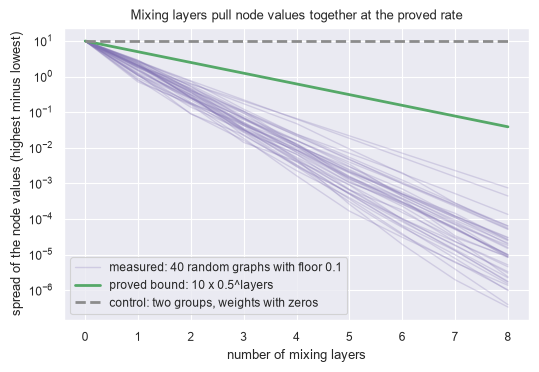

In [3]:
figure, axis = plt.subplots(figsize=(6, 3.8))
layers = np.arange(LAYER_COUNT + 1)
for trial in range(40):
    axis.plot(layers, spreads[trial], color=MODEL, alpha=0.25, linewidth=1,
              label="measured: 40 random graphs with floor 0.1" if trial == 0 else None)
axis.plot(layers, bounds, color=BOUND, linewidth=2, label="proved bound: 10 x 0.5^layers")
axis.plot(layers, control_spreads, color=BEFORE, linewidth=2, linestyle="--", label="control: two groups, weights with zeros")
axis.set_yscale("log")
axis.set_xlabel("number of mixing layers")
axis.set_ylabel("spread of the node values (highest minus lowest)")
axis.set_title("Mixing layers pull node values together at the proved rate")
axis.legend(loc="lower left")
save_figure(figure, "38-oversmoothing")
plt.show()

## Claim 2: the signal's share is `(1 - noise_rate)^step_count` (`signal_share_after_many_noising_steps`, `noising_step_keeps_total_variance_at_one`)

Start from (signal, noise) = (1, 0) and apply a step with `noise_rate` 0.1 ten times, then for the rates 0.01, 0.1, 0.5
and 0.9 apply it up to 50 times.

**Prediction.** After 10 steps at 0.1 the signal share is `0.9^10 = 0.3487` and the noise share `0.6513`; at every step
of every rate the signal equals `(1 - rate)^k` to 1e-12 relative, and the two shares add to one. **Against the claim:** any
step where the closed form and the iteration differ by more than 1e-12 relative.

**Control.** A schedule whose rate changes from step to step (0.02, 0.18, repeating) is not the single-rate schedule: the
closed form with the mean rate 0.1 must then be wrong, and by how much is reported.

The first three checks iterate the step's own formula, so they are "from the formula", not measured (the last of them is by
construction). The measured check samples the noising 400 000 times and reads the signal's share of the variance.

In [4]:
NOISE_RATE = 0.1
split = (1.0, 0.0)
for step in range(10):
    split = take_noising_step(NOISE_RATE, split)
signal_after_ten, noise_after_ten = split
print(f"after 10 steps at rate 0.1: signal {signal_after_ten:.4f}, noise {noise_after_ten:.4f}")

worst_relative = 0.0
worst_sum_gap = 0.0
for noise_rate in (0.01, 0.1, 0.5, 0.9):
    split = (1.0, 0.0)
    for step_count in range(1, 51):
        split = take_noising_step(noise_rate, split)
        expected = (1 - noise_rate) ** step_count
        worst_relative = max(worst_relative, abs(split[0] - expected) / expected)
        worst_sum_gap = max(worst_sum_gap, abs(split[0] + split[1] - 1.0))
report("from the formula: iterating the step gives signal (1 - rate)^steps, for four rates",
       worst_relative < 1e-12, f"largest relative gap {worst_relative:.1e}")
report("from the formula: the two shares add to one", worst_sum_gap < 1e-12, f"largest gap {worst_sum_gap:.1e}")
print(f"[by construction, cannot fail, not evidence] ten steps at 0.1 leave signal 0.9^10 = {signal_after_ten:.4f}")

split = (1.0, 0.0)
for step in range(10):
    split = take_noising_step(0.02 if step % 2 == 0 else 0.18, split)
mean_rate_signal = 0.9 ** 10
varying_gap = abs(split[0] - mean_rate_signal)
report("from the formula, control: a schedule with changing rates does not follow the closed form with the mean rate",
       varying_gap > 1e-3, f"signal {split[0]:.4f} against {mean_rate_signal:.4f}, gap {varying_gap:.4f}")

# a real measurement: sample the noising. Each step is x -> sqrt(1 - rate) * x + sqrt(rate) * fresh noise,
# the signal is the starting x, and its share of the variance is the squared correlation of x with it.
generator = np.random.default_rng(SEED + 2)
SAMPLE_COUNT = 400_000
signal = generator.standard_normal(SAMPLE_COUNT)
sampled = signal.copy()
for step in range(10):
    sampled = np.sqrt(1 - NOISE_RATE) * sampled + np.sqrt(NOISE_RATE) * generator.standard_normal(SAMPLE_COUNT)
sampled_share = float(np.corrcoef(sampled, signal)[0, 1] ** 2)
standard_error = 2 * (1 - sampled_share) * np.sqrt(sampled_share) / np.sqrt(SAMPLE_COUNT)   # rough, from the correlation's own error
report("measured: in 400 000 sampled noisings, ten steps at 0.1 leave signal share 0.9^10 within 0.01",
       abs(sampled_share - 0.9 ** 10) < 0.01, f"sampled share {sampled_share:.4f}, 0.9^10 = {0.9 ** 10:.4f}")


after 10 steps at rate 0.1: signal 0.3487, noise 0.6513
[PASS] from the formula: iterating the step gives signal (1 - rate)^steps, for four rates  (largest relative gap 4.1e-16)
[PASS] from the formula: the two shares add to one  (largest gap 2.2e-16)
[by construction, cannot fail, not evidence] ten steps at 0.1 leave signal 0.9^10 = 0.3487
[PASS] from the formula, control: a schedule with changing rates does not follow the closed form with the mean rate  (signal 0.3351 against 0.3487, gap 0.0136)
[PASS] measured: in 400 000 sampled noisings, ten steps at 0.1 leave signal share 0.9^10 within 0.01  (sampled share 0.3494, 0.9^10 = 0.3487)


True

## Claim 3: guidance is not an average (`guidance_is_not_an_average`, `guidance_moves_along_the_prompt_direction`, `guided_step_is_longer_by_one_plus_strength`)

The model is two prediction vectors in 8 dimensions, `without_prompt` and `with_prompt`, drawn from a standard normal
(1000 pairs), and 12 strengths from 0.1 to 5. The guided prediction is `(1 + strength) * with_prompt - strength * without_prompt`.

**Prediction.** For every pair and every positive strength, the guided prediction is off the stretch between the two
predictions (distance to the stretch above 1e-9), and its distance from `without_prompt` is `(1 + strength)` times the
plain step's length (to 1e-9). **Against the claim:** one guided point on the stretch.

**Control.** Strengths from -1 to 0 give weights `1 + strength` and `-strength`, both at least 0, so that is an
average and the guided point must lie on the stretch (distance below 1e-9). That is the hypothesis `0 < strength`
broken.

These numbers are "from the formula" (guidance is one formula applied to sampled vectors), and the check of the move's
length is by construction.

In [5]:
generator = np.random.default_rng(SEED + 3)
DIMENSION = 8
PAIR_COUNT = 1000
POSITIVE_STRENGTHS = np.linspace(0.1, 5.0, 12)
NEGATIVE_STRENGTHS = np.linspace(-1.0, 0.0, 12)

smallest_distance = np.inf
worst_scale_gap = 0.0
largest_control_distance = 0.0
for pair in range(PAIR_COUNT):
    without_prompt = generator.standard_normal(DIMENSION)
    with_prompt = generator.standard_normal(DIMENSION)
    plain_length = np.linalg.norm(with_prompt - without_prompt)
    for strength in POSITIVE_STRENGTHS:
        guided = apply_guidance(strength, without_prompt, with_prompt)
        smallest_distance = min(smallest_distance, get_distance_to_segment(guided, without_prompt, with_prompt))
        guided_length = np.linalg.norm(guided - without_prompt)
        worst_scale_gap = max(worst_scale_gap, abs(guided_length / plain_length - (1 + strength)))
    for strength in NEGATIVE_STRENGTHS:
        guided = apply_guidance(strength, without_prompt, with_prompt)
        largest_control_distance = max(largest_control_distance, get_distance_to_segment(guided, without_prompt, with_prompt))
report("from the formula: every guided point with positive strength is off the stretch", smallest_distance > 1e-9,
       f"smallest distance to the stretch {smallest_distance:.3f} over {PAIR_COUNT * len(POSITIVE_STRENGTHS)} cases")
print(f"[by construction, cannot fail, not evidence] the guided move is (1 + strength) times the plain move, largest gap {worst_scale_gap:.1e}")
report("from the formula, control: strengths from -1 to 0 stay on the stretch", largest_control_distance < 1e-9,
       f"largest distance {largest_control_distance:.1e}")

[PASS] from the formula: every guided point with positive strength is off the stretch  (smallest distance to the stretch 0.119 over 12000 cases)
[by construction, cannot fail, not evidence] the guided move is (1 + strength) times the plain move, largest gap 2.7e-15
[PASS] from the formula, control: strengths from -1 to 0 stay on the stretch  (largest distance 2.3e-15)


True

wrote book/figures/38-guidance-off-the-stretch.png


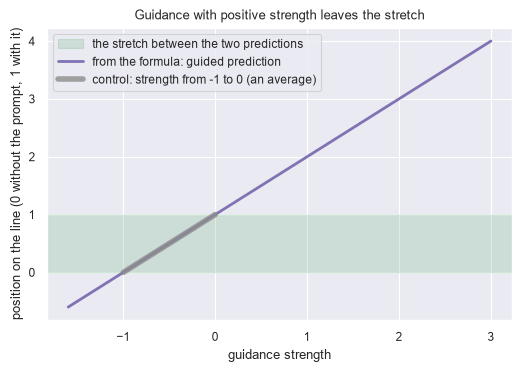

In [6]:
generator = np.random.default_rng(SEED + 4)
without_prompt = generator.standard_normal(DIMENSION)
with_prompt = generator.standard_normal(DIMENSION)
step = with_prompt - without_prompt
strengths = np.linspace(-1.6, 3.0, 47)
positions = np.array([np.dot(apply_guidance(strength, without_prompt, with_prompt) - without_prompt, step) / np.dot(step, step)
                      for strength in strengths])
figure, axis = plt.subplots(figsize=(6, 3.8))
axis.axhspan(0.0, 1.0, color=BOUND, alpha=0.2, label="the stretch between the two predictions")
axis.plot(strengths, positions, color=MODEL, linewidth=2, label="from the formula: guided prediction")
inside = (strengths >= -1.0) & (strengths <= 0.0)
axis.plot(strengths[inside], positions[inside], color=BEFORE, linewidth=4, alpha=0.8,
          label="control: strength from -1 to 0 (an average)")
axis.set_xlabel("guidance strength")
axis.set_ylabel("position on the line (0 without the prompt, 1 with it)")
axis.set_title("Guidance with positive strength leaves the stretch")
axis.legend(loc="upper left")
save_figure(figure, "38-guidance-off-the-stretch")
plt.show()

## Claim 4: averaging over moves of the input (`averaged_model_ignores_the_moves`, `averaged_model_is_no_steeper`)

The moves are the 8 circular shifts of an input vector in 8 dimensions. The model is `norm(input) + input[0]`. The norm is
1-Lipschitz and the coordinate is 1-Lipschitz, so the model is 2-Lipschitz, and the constant 2 is reached (along the first axis).
I average it over the shifts and compare 2000 random pairs of inputs.

**Prediction.** The averaged model gives the same value at an input and at a shift of it (to 1e-12), and its change per
distance, on every pair, is at most 2. **Against the claim:** a shifted input with a different averaged value, or a ratio
above 2.

**Control.** Moves that do not keep distances: scale the input by 1 or by 3, average over those, with the model
`input[0]`, which is exactly 1-Lipschitz. The average is `2 * input[0]`, and its ratio must exceed 1.

In [7]:
generator = np.random.default_rng(SEED + 5)
INPUT_SIZE = 8


def evaluate_model(model_input):
    return np.linalg.norm(model_input) + model_input[0]


def average_over_shifts(model, model_input):
    return np.mean([model(np.roll(model_input, shift)) for shift in range(INPUT_SIZE)])


largest_invariance_gap = 0.0
largest_ratio = 0.0
largest_model_ratio = 0.0
for pair in range(2000):
    first = generator.standard_normal(INPUT_SIZE)
    second = first + generator.standard_normal(INPUT_SIZE) * generator.choice([0.01, 0.1, 1.0])
    shift = int(generator.integers(1, INPUT_SIZE))
    gap = abs(average_over_shifts(evaluate_model, first) - average_over_shifts(evaluate_model, np.roll(first, shift)))
    largest_invariance_gap = max(largest_invariance_gap, gap)
    distance = np.linalg.norm(first - second)
    largest_ratio = max(largest_ratio, abs(average_over_shifts(evaluate_model, first) - average_over_shifts(evaluate_model, second)) / distance)
    largest_model_ratio = max(largest_model_ratio, abs(evaluate_model(first) - evaluate_model(second)) / distance)
MODEL_CONSTANT = 2.0
report("the shift-averaged model gives the same value at every shift of an input", largest_invariance_gap < 1e-12,
       f"largest gap {largest_invariance_gap:.1e}")
report("the shift-averaged model is no steeper than the model's constant", largest_ratio <= MODEL_CONSTANT,
       f"averaged ratio {largest_ratio:.3f}, model's own {largest_model_ratio:.3f}, constant {MODEL_CONSTANT}")

largest_scaled_ratio = 0.0
for pair in range(2000):
    first = generator.standard_normal(INPUT_SIZE)
    second = first + 0.1 * generator.standard_normal(INPUT_SIZE)
    averaged_first = np.mean([scale * first[0] for scale in (1.0, 3.0)])
    averaged_second = np.mean([scale * second[0] for scale in (1.0, 3.0)])
    largest_scaled_ratio = max(largest_scaled_ratio, abs(averaged_first - averaged_second) / np.linalg.norm(first - second))
report("control: averaging over scalings (not distance-keeping) makes a model steeper than its constant 1",
       largest_scaled_ratio > 1.0, f"largest ratio {largest_scaled_ratio:.3f}")

[PASS] the shift-averaged model gives the same value at every shift of an input  (largest gap 8.9e-16)
[PASS] the shift-averaged model is no steeper than the model's constant  (averaged ratio 1.084, model's own 1.599, constant 2.0)
[PASS] control: averaging over scalings (not distance-keeping) makes a model steeper than its constant 1  (largest ratio 1.831)


True

## Claim 5: a baseline changes no average push (`baseline_pushes_nothing_on_average`, `subtracting_a_baseline_keeps_the_average_push`)

The model is a softmax policy over 4 actions with logits (0.3, -0.5, 1.1, 0.0). The push on the logits for action `a` is
the one-hot of `a` minus the policy. For 200 random reward vectors and 5 baselines each, compute the average over the
action taken of `(reward - baseline) * push`.

**Prediction.** The average of the push alone is zero (to 1e-12), and the average with any constant baseline equals the
average with no baseline (to 1e-12). **Against the claim:** a baseline that changes the average.

**Control.** A baseline that depends on the action (here the reward itself) is not constant: the average push should
change (to zero), and the size of the change is reported.

In [8]:
generator = np.random.default_rng(SEED + 6)
LOGITS = np.array([0.3, -0.5, 1.1, 0.0])
policy = np.exp(LOGITS) / np.exp(LOGITS).sum()
pushes = np.eye(4) - policy           # row a is the push when action a is taken
average_push = policy @ pushes
report("the average push of a softmax policy is zero", np.abs(average_push).max() < 1e-12,
       f"largest entry {np.abs(average_push).max():.1e}")

largest_change = 0.0
largest_push = 0.0
for trial in range(200):
    rewards = generator.normal(size=4)
    plain = (policy * rewards) @ pushes
    largest_push = max(largest_push, np.abs(plain).max())
    for baseline in generator.normal(size=5):
        with_baseline = (policy * (rewards - baseline)) @ pushes
        largest_change = max(largest_change, np.abs(with_baseline - plain).max())
report("a constant baseline changes no average push", largest_change < 1e-12,
       f"largest change {largest_change:.1e}, against pushes up to {largest_push:.2f}")

acting_baseline_push = (policy * (rewards - rewards)) @ pushes
acting_change = np.abs(acting_baseline_push - plain).max()
report("control: a baseline equal to the reward of the action taken changes the average push", acting_change > 1e-3,
       f"change {acting_change:.3f}")

[PASS] the average push of a softmax policy is zero  (largest entry 2.1e-17)
[PASS] a constant baseline changes no average push  (largest change 2.2e-16, against pushes up to 0.91)
[PASS] control: a baseline equal to the reward of the action taken changes the average push  (change 0.078)


True

## Claim 6: absolute error is least at a median (`absolute_error_is_least_at_a_median`)

The labels are 1, 2 and 100 from the chapter, then 500 random sets of 7 labels from a heavy-tailed (Cauchy) distribution.
For the chapter's labels search a constant on a grid of spacing 0.01 from 0 to 100 for the least squared error and the
least absolute error.

**Prediction.** The squared error is least at the mean 34.33 and the absolute error at 2 (both within the grid spacing).
For each random set, the sum of absolute errors at the median is no more than at 200 random constants.
**Against the claim:** a constant with less absolute error than the median.

**Control.** The mean has more absolute error than the median on the chapter's labels, by a reported amount.

In [9]:
generator = np.random.default_rng(SEED + 7)
labels = np.array([1.0, 2.0, 100.0])
grid = np.arange(0.0, 100.0 + 0.005, 0.01)
squared = ((grid[:, None] - labels) ** 2).sum(axis=1)
absolute = np.abs(grid[:, None] - labels).sum(axis=1)
best_squared, best_absolute = float(grid[squared.argmin()]), float(grid[absolute.argmin()])
report("squared error is least at the mean, absolute error at the median, for labels 1, 2, 100",
       abs(best_squared - labels.mean()) <= 0.01 and abs(best_absolute - np.median(labels)) <= 0.01,
       f"squared least at {best_squared:.2f} (mean {labels.mean():.2f}), absolute least at {best_absolute:.2f} (median {np.median(labels):.0f})")

worst_margin = np.inf
for trial in range(500):
    label_set = generator.standard_cauchy(7)
    median_cost = np.abs(label_set - np.median(label_set)).sum()
    others = generator.uniform(label_set.min(), label_set.max(), 200)
    costs = np.abs(others[:, None] - label_set).sum(axis=1)
    worst_margin = min(worst_margin, float(costs.min() - median_cost))
report("no random constant beats the median in absolute error, over 500 label sets", worst_margin >= -1e-12,
       f"smallest (other minus median) {worst_margin:.1e}")

mean_cost = float(np.abs(labels.mean() - labels).sum())
median_cost = float(np.abs(np.median(labels) - labels).sum())
report("control: the mean has more absolute error than the median", mean_cost > median_cost + 1.0,
       f"{mean_cost:.2f} at the mean, {median_cost:.2f} at the median")

[PASS] squared error is least at the mean, absolute error at the median, for labels 1, 2, 100  (squared least at 34.33 (mean 34.33), absolute least at 2.00 (median 2))
[PASS] no random constant beats the median in absolute error, over 500 label sets  (smallest (other minus median) 7.7e-08)
[PASS] control: the mean has more absolute error than the median  (131.33 at the mean, 99.00 at the median)


True

## Claim 7: random directions overlap with mean square `mean_square * length^2` (`random_directions_are_nearly_at_right_angles`)

The random vector has independent random-sign coordinates of size `sigma`, so each coordinate has mean square `sigma^2`
and distinct ones are uncorrelated. Two runs. In 10 dimensions with `sigma` = 0.7 all 1024 sign patterns can be listed, so the
average is exact. In 100 dimensions with `sigma = 1 / sqrt(100) = 0.1` (so `mean_square` = 0.01) a random unit direction is
tried on 200 000 draws.

**Prediction.** For 20 random directions in 10 dimensions the exact mean square overlap equals `0.49 * length^2` to 1e-12
relative. In 100 dimensions the mean square overlap of a unit direction is 0.01, within 4 standard errors.
**Against the claim:** an exact gap above 1e-12, or a draw average more than 4 standard errors from 0.01.

**Control.** Make coordinate 1 a copy of coordinate 0 (correlated), with a direction that has weight on both. The mean
square overlap must then differ from `mean_square * length^2`.

In [10]:
generator = np.random.default_rng(SEED + 8)
SIGMA = 0.7
SMALL_DIMENSION = 10
patterns = np.array(list(itertools.product([-1.0, 1.0], repeat=SMALL_DIMENSION)))
vectors = SIGMA * patterns                        # all outcomes, each with chance 1/1024
worst_gap = 0.0
for trial in range(20):
    direction = generator.normal(size=SMALL_DIMENSION)
    exact = float(np.mean((vectors @ direction) ** 2))
    expected = SIGMA ** 2 * float(direction @ direction)
    worst_gap = max(worst_gap, abs(exact - expected) / expected)
report("exact mean square overlap is mean_square times the squared length, in 10 dimensions", worst_gap < 1e-12,
       f"largest relative gap {worst_gap:.1e}, over 20 directions")

BIG_DIMENSION = 100
DRAW_COUNT = 200_000
size = 1.0 / np.sqrt(BIG_DIMENSION)
signs = generator.choice([-1.0, 1.0], size=(DRAW_COUNT, BIG_DIMENSION))
random_direction = generator.normal(size=BIG_DIMENSION)
random_direction /= np.linalg.norm(random_direction)
overlaps = (size * signs) @ random_direction
mean_square_overlap = float(np.mean(overlaps ** 2))
standard_error = float(np.std(overlaps ** 2) / np.sqrt(DRAW_COUNT))
report("in 100 dimensions a random unit direction has mean square overlap 0.01, within four standard errors",
       abs(mean_square_overlap - 0.01) < 4 * standard_error, f"measured {mean_square_overlap:.5f} +- {standard_error:.1e}")

correlated = vectors.copy()
correlated[:, 1] = correlated[:, 0]
direction = np.zeros(SMALL_DIMENSION)
direction[:2] = 1.0
correlated_value = float(np.mean((correlated @ direction) ** 2))
expected = SIGMA ** 2 * float(direction @ direction)
report("control: correlated coordinates break the formula", abs(correlated_value - expected) > 0.1,
       f"measured {correlated_value:.3f}, the formula gives {expected:.3f}")

[PASS] exact mean square overlap is mean_square times the squared length, in 10 dimensions  (largest relative gap 3.0e-16, over 20 directions)


[PASS] in 100 dimensions a random unit direction has mean square overlap 0.01, within four standard errors  (measured 0.00998 +- 3.1e-05)


[PASS] control: correlated coordinates break the formula  (measured 1.960, the formula gives 0.980)


True

## Summary

Everything above is a check on small models by measurement. It is evidence, not proof. The measured numbers are in the
`[PASS]` lines; the chapter copies them.